# IMDb Movie Review Sentiment & Theme Analyzer

## 1. Exploratory Data Analysis (EDA)

**Objective:** Understand the dataset's structure, quality, sentiment distribution, and review characteristics before preprocessing and modelling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

%matplotlib inline

#### Loading the dataset

In [2]:
data_path = Path("../dataset/raw/IMDB Dataset.csv")

df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


In [4]:
print("Column names: ", df.columns.tolist())
print("\nData types: ")
print(df.dtypes)

Column names:  ['review', 'sentiment']

Data types: 
review       str
sentiment    str
dtype: object


In [5]:
for i, row in df.head(3).iterrows():
    print(f"\nReview {i+1}")
    print(f"Sentiment: {row['sentiment']}")
    print(f"Review: {row['review'][:500]}")
    print("-" * 80)


Review 1
Sentiment: positive
Review: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ
--------------------------------------------------------------------------------

Review 2
Sentiment: positive
Review: A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! Yo

From the above output it can be seen that some html tags are present in reviews. We'll handle them later during preprocessing.

In [6]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values: ", df.isnull().sum().sum())

Missing values per column:
review       0
sentiment    0
dtype: int64

Total missing values:  0


In [8]:
print("Exact duplicate rows: ", df.duplicated().sum())
print("\nDuplicate Review Texts: ", df["review"].duplicated().sum())

Exact duplicate rows:  418

Duplicate Review Texts:  418


sentiment
positive    25000
negative    25000
Name: count, dtype: int64


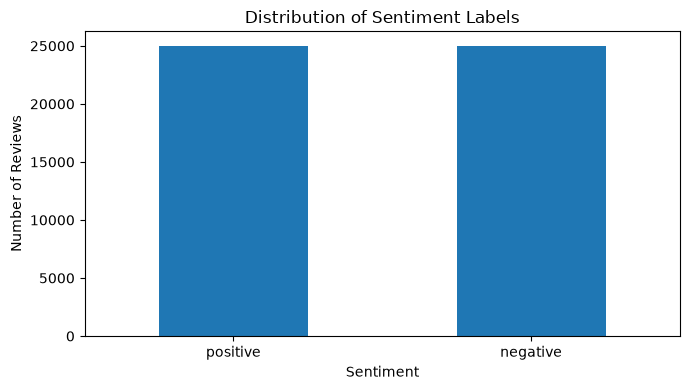

In [9]:
sentiment_counts = df['sentiment'].value_counts()
print(sentiment_counts)

sentiment_counts.plot(kind='bar', figsize=(7,4), rot=0)

plt.title("Distribution of Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [10]:
sentiment_percentages = (
    df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(sentiment_percentages)

sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64


In [11]:
df['word_count'] = df['review'].str.split().str.len()

df[['sentiment', 'word_count']].groupby('sentiment')['word_count'].describe()

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,25000.0,229.46456,164.947795,4.0,128.0,174.0,278.0,1522.0
positive,25000.0,232.84932,177.497046,10.0,125.0,172.0,284.0,2470.0


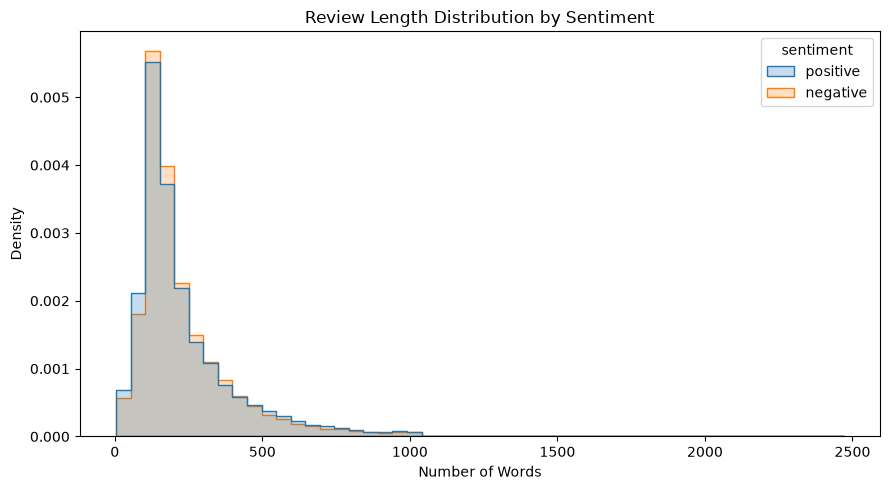

In [12]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='word_count',
    hue='sentiment',
    bins=50,
    element='step',
    stat='density',
    common_norm=False
)

plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Number of Words")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

Investigating the duplicate reviews found earlier

In [13]:
duplicate_reviews = df[
    df["review"].duplicated(keep=False)
].sort_values("review")

print("Rows belonging to duplicated reviews:", len(duplicate_reviews))

print(
    "Unique sentiments among duplicated review texts:",
    duplicate_reviews.groupby("review")["sentiment"].nunique().value_counts()
)

Rows belonging to duplicated reviews: 824
Unique sentiments among duplicated review texts: sentiment
1    406
Name: count, dtype: int64


In [15]:
conflicting_reviews = (
    df.groupby("review")["sentiment"]
    .nunique()
    .loc[lambda x: x > 1]
)

print("Review texts with conflicting sentiment labels:", len(conflicting_reviews))

Review texts with conflicting sentiment labels: 0


In [16]:
for sentiment in ["positive", "negative"]:
    print(f"\n{'=' * 20} {sentiment.upper()} REVIEW {'=' * 20}")

    sample_review = df.loc[
        df["sentiment"] == sentiment, "review"
    ].iloc[0]

    print(sample_review[:1000])


==================== POSITIVE REVIEW ====================
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br 

## EDA Summary

- The dataset contains 50,000 movie reviews with two columns: review and sentiment.
- There are no missing values.
- The sentiment classes are balanced, with 25,000 positive and 25,000 negative reviews.
- There are 418 extra rows from duplicated review texts, with no conflicting sentiment labels.
- Review lengths vary considerably, with typical reviews containing around 172–174 words by the median.
- Some reviews are exceptionally long, so text length may need consideration when selecting a modelling approach.

### Next steps
Remove duplicate reviews, clean the text carefully, and prepare the dataset for sentiment classification and keyphrase extraction.